## Short-Term Memory

### 一、快速实现短期记忆

`create_agent` + `checkpointer` + `thread_id`

In [1]:
from langchain.agents import create_agent
from langchain.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver # 内存存储 checkpointer

# 创建智能体时指定checkpointer，LangChain会自动帮我们管理历史会话记忆
agent = create_agent(
    "deepseek-chat",
    checkpointer=InMemorySaver()
)

# 设定thread_id，作为会话标识
config = {"configurable": {"thread_id": "thread_1"}}

# 第一次调用，告知AI我的信息
response = agent.invoke(
    {"messages": [HumanMessage(content="你好，我叫虎哥，我最喜欢猫猫。")]},
    config # 调用时添加thread_id，区分不同会话
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

你好，我叫虎哥，我最喜欢猫猫。
================================== Ai Message ==================================

虎哥你好呀！猫猫确实超级可爱，毛茸茸软乎乎的，光是看着就让人心情变好～你是自己养了猫猫，还是喜欢云吸猫呢？😺 如果有猫猫的故事或者照片（描述也行！），随时欢迎分享～


In [2]:
# 第二次调用，询问我的信息，这次带上thread_id，唤起记忆
response = agent.invoke(
    {"messages": [HumanMessage(content="我叫什么，我最喜欢的动物是什么？")]},
    config # 调用时添加thread_id
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

你好，我叫虎哥，我最喜欢猫猫。
================================== Ai Message ==================================

虎哥你好呀！猫猫确实超级可爱，毛茸茸软乎乎的，光是看着就让人心情变好～你是自己养了猫猫，还是喜欢云吸猫呢？😺 如果有猫猫的故事或者照片（描述也行！），随时欢迎分享～
================================ Human Message =================================

我叫什么，我最喜欢的动物是什么？
================================== Ai Message ==================================

你叫**虎哥**，你最喜欢的动物是**猫猫**！🐱 我记得很清楚哦～ 有什么关于猫猫的话题想聊吗？


### 二、短期记忆详解



**短期记忆 =  `State` 状态容器 + `Checkpointer` 快照持久化 + `thread_id` 会话隔离**
- **AgentState（状态容器）**：里面的 `messages` 字段存会话历史，本质是一个带 `reducer` 的 `TypedDict`
- **Checkpointer（快照持久化）**：每次与AI交互都会生成一个快照，在 LangChain 中，快照是通过 `Checkpointer` 对象来保存的
    - 会话历史：最后一个快照
    - 时光回溯：通过快照链实现，找到指定快照，再从该快照开始给模型发消息生成回复
- **thread_id**（会话隔离）：会话标识，用于区分不同会话

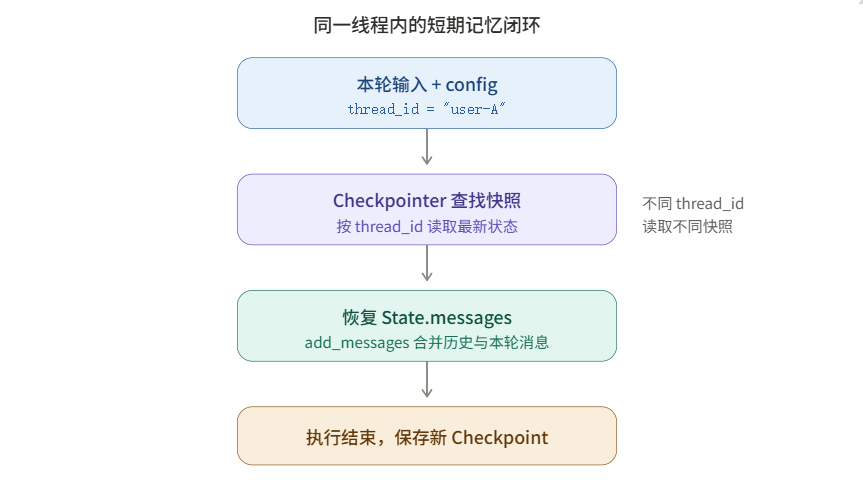

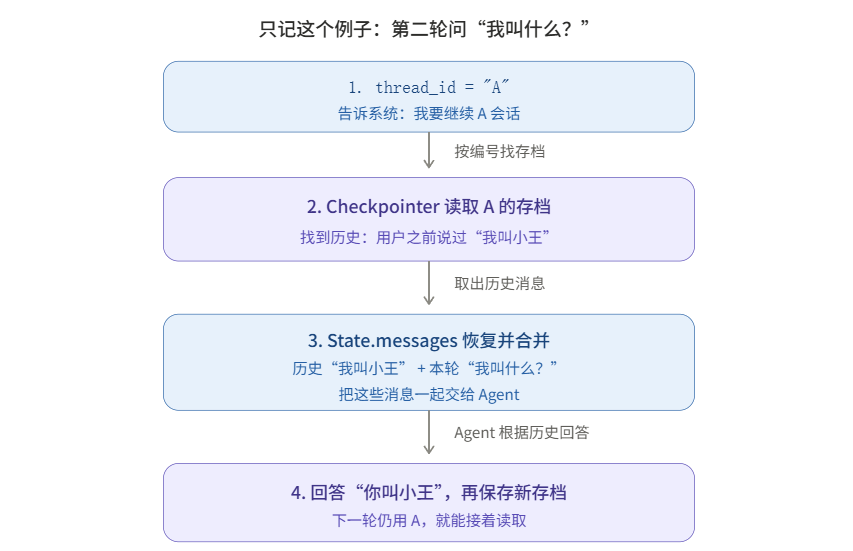

### 三、State（状态容器）

#### 3.1 AgentState：本质上是一个带 `reducer` 的 `TypedDict`


In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage

class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]   # ← reducer = add_messages
    # 其他字段...

`Annotated[T, reducer]`：`T` 是字段类型，`reducer` 是合并函数。没有 `reducer` 的字段默认覆盖（新值直接替换旧值）。

#### 3.2 LangGraph 中预定义实现 `MessagesState`

In [ ]:
from langgraph.graph import MessagesState

自定义 State 时继承它即可只关心额外字段：

In [ ]:
class State(MessagesState):
    summary: str
    user_profile: dict

#### 3.3 `create_agent` 内部构建的 State 除了 `messages` 字段外，还包含其他字段


- `messages`：会话历史
- `remaining_steps`：剩余可执行步数（防止死循环）
- `structured_response`：结构化输出（`response_format`启用时）
- `jump_to`：图内跳转控制信号

#### 3.4 State 的生命周期（一次 invoke 内）

```
invoke(input, config)
  → 加载最新 checkpoint 还原 state（若无则初始化）
  → 合并 input（走 add_messages）
  → 逐个节点执行，节点返回增量 → reducer 合并 → 产生新 state
  → 每个 super-step 结束 → 写一个新 checkpoint
  → 返回最终 state
```

`每个节点看到的都是"截至当前的完整 state"`，这是理解 checkpointer 的前提

### 四、Checkpointer（快照持久化）

| | Checkpointer                                | Store |
|---|---------------------------------------------|---|
| **存什么** | 单个 thread 的 state 快照链                       | 跨 thread 的键值/向量记忆 |
| **键** | `(thread_id, checkpoint_ns, checkpoint_id)` | `(namespace, key)` |
| **用途** | 短期记忆、中断恢复、时间回溯                              | 长期记忆（用户偏好、事实） |
| **典型实现** | `PostgresSaver`                             | `PostgresStore`  |

```pyhton
graph = builder.compile(checkpointer=cp, store=store)  # 可同时挂载
```

在 LangChain 中， 快照都是通过 `Checkpointer` 对象来保存的，它有很多不同的实现：
- `InMemorySaver`：基于内存存储
- `SqliteSaver`：基于 sqlite 数据库存储
- `PostgreSaver`：基于 PostgreSql 数据存储

### 五、Thread_id（会话隔离）

thread_id 是 **Checkpointer 的顶层命名空间**，通过 config 传入：
```python
config = {"configurable": {"thread_id": "{tenant_id}:{user_id}:{session_id}"}}
graph.invoke(input, config)
```

**一个 thread_id ↔ 一条独立的 checkpoint 快照链 ↔ 一段独立对话历史**

#####